**PyGPT ( python genertive pretrained transformer )
**

In [9]:
!pip install -q datasets transformers torch tqdm matplotlib

import os
import torch
from datasets import load_dataset
from transformers import AutoTokenizer

# Load the Python Code Dataset (tiny-codes)
print("Loading dataset...")
ds = load_dataset("nampdn-ai/tiny-codes", split="train")

# Train/Validation split
ds_split = ds.train_test_split(test_size=0.05, seed=42)
train_ds = ds_split['train']
val_ds = ds_split['test']

Loading dataset...


part_7_1400000.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

part_7_1400000.parquet: downloading bytes:           |  0.00B            

part_8_1600000.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

part_8_1600000.parquet: downloading bytes:           |  0.00B            

part_9_1632520.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

part_9_1632520.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1632309 [00:00<?, ? examples/s]

### Hugging Face Authentication

We will securely load the Hugging Face token from Colab Secrets and set it as an environment variable. This allows Hugging Face libraries like `datasets` and `transformers` to automatically authenticate and download gated datasets.

In [4]:
import os
from google.colab import userdata

try:
    # Retrieve the token from Colab Secrets
    HF_TOKEN = userdata.get('HF_TOKEN')

    # Set it as an environment variable
    os.environ["HF_TOKEN"] = HF_TOKEN
    print("Successfully set HF_TOKEN environment variable!")
except Exception as e:
    print("Error retrieving HF_TOKEN. Please ensure you have added 'HF_TOKEN' to your Colab Secrets (the 🔑 icon on the left panel).")

Successfully set HF_TOKEN environment variable!


Now you can run the cell below to load your dataset.

In [13]:
import os
import numpy as np
from tqdm.auto import tqdm
from transformers import AutoTokenizer

# Ensure the dataset variables are available
if 'train_ds' not in globals() or 'val_ds' not in globals():
    raise ValueError("Dataset variables 'train_ds' or 'val_ds' not found. Please make sure the previous dataset-loading cell completes successfully first!")

# Retrieve the token from environment variables
token = os.environ.get("HF_TOKEN")

# Load StarCoder Code Tokenizer with token authentication
print("Loading StarCoder tokenizer...")
tokenizer = AutoTokenizer.from_pretrained("bigcode/starcoder", token=token)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Determine the available text/code column dynamically
available_columns = train_ds.column_names
print(f"Dataset columns: {available_columns}")

# Determine which column to tokenise (prefer 'code' or 'response', fall back to the first string column)
text_col = None
for candidate in ['code', 'response', 'prompt', 'text']:
    if candidate in available_columns:
        text_col = candidate
        break
if not text_col:
    text_col = available_columns[0]
print(f"Using column '{text_col}' for tokenization.")

def process(example):
    # Encode snippets into token IDs dynamically using the detected column
    ids = tokenizer.encode(example[text_col], truncation=True, max_length=2048)
    return {'ids': ids, 'len': len(ids)}

# Tokenize and save as binary files
for split_name, dset in [('train', train_ds), ('validation', val_ds)]:
    filename = f"{split_name}.bin"
    if not os.path.exists(filename):
        print(f"Tokenizing {split_name} split...")
        tokenized = dset.map(
            process,
            remove_columns=dset.column_names,
            desc=f"Tokenizing {split_name}",
            num_proc=4
        )

        arr_len = np.sum(tokenized['len'], dtype=np.uint64)
        # uint32 is required because StarCoder vocab_size (49,152) exceeds uint16 max (65,535)
        dtype = np.uint32
        arr = np.memmap(filename, dtype=dtype, mode='w+', shape=(arr_len,))

        total_batches = 100
        idx = 0
        for batch_idx in tqdm(range(total_batches), desc=f'Writing {filename}'):
            batch = tokenized.shard(num_shards=total_batches, index=batch_idx, contiguous=True).with_format('numpy')
            arr_batch = np.concatenate(batch['ids'])
            arr[idx : idx + len(arr_batch)] = arr_batch
            idx += len(arr_batch)
        arr.flush()

Loading StarCoder tokenizer...
Dataset columns: ['prompt', 'main_topic', 'subtopic', 'adjective', 'action_verb', 'scenario', 'target_audience', 'programming_language', 'common_sense_topic', 'idx', 'response']
Using column 'response' for tokenization.
Tokenizing train split...


Tokenizing train (num_proc=4):   0%|          | 0/1550693 [00:00<?, ? examples/s]

Writing train.bin:   0%|          | 0/100 [00:00<?, ?it/s]

Tokenizing validation split...


Tokenizing validation (num_proc=4):   0%|          | 0/81616 [00:00<?, ? examples/s]

Writing validation.bin:   0%|          | 0/100 [00:00<?, ?it/s]

In [15]:
# Batch retrieval from memory-mapped files
def get_batch(split):
    if split == 'train':
        data = np.memmap('train.bin', dtype=np.uint32, mode='r')
    else:
        data = np.memmap('validation.bin', dtype=np.uint32, mode='r')

    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])

    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

In [16]:
import torch.nn as nn
import torch.nn.functional as F
import math
from dataclasses import dataclass

class LayerNorm(nn.Module):
    def __init__(self, ndim, bias):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None

    def forward(self, x):
        return F.layer_norm(x, self.weight.shape, self.weight, self.bias, 1e-5)

# --- Rotary Position Embeddings (RoPE) Helper Functions ---
class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len=2048):
        super().__init__()
        inv_freq = 1.0 / (10000 ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer("inv_freq", inv_freq)

    def forward(self, seq_len, device):
        t = torch.arange(seq_len, device=device).type_as(self.inv_freq)
        freqs = torch.einsum("i,j->ij", t, self.inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        return emb.cos(), emb.sin()

def apply_rotary_pos_emb(q, k, cos, sin):
    def rotate_half(x):
        x1 = x[..., :x.shape[-1] // 2]
        x2 = x[..., x.shape[-1] // 2:]
        return torch.cat((-x2, x1), dim=-1)

    q_embed = (q * cos) + (rotate_half(q) * sin)
    k_embed = (k * cos) + (rotate_half(k) * sin)
    return q_embed, k_embed

# --- Causal Attention with RoPE Integration ---
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head
        self.rotary_emb = RotaryEmbedding(self.head_dim)

        self.flash = hasattr(F, 'scaled_dot_product_attention')
        if not self.flash:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                           .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Apply RoPE to Queries and Keys
        cos, sin = self.rotary_emb(T, device=x.device)
        q, k = apply_rotary_pos_emb(q, k, cos[None, None, :, :], sin[None, None, :, :])

        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=None, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.resid_dropout(self.c_proj(y))
        return y

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln1 = LayerNorm(config.n_embd, config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln2 = LayerNorm(config.n_embd, config.bias)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 512
    vocab_size: int = 49152  # Updated to StarCoder vocab size
    n_layer: int = 8
    n_head: int = 8
    n_embd: int = 512
    dropout: float = 0.1
    bias: bool = False

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        # Removed wpe (absolute positional embedding) since RoPE handles positions
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=LayerNorm(config.n_embd, config.bias),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight  # Weight tying

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        b, t = idx.size()
        tok_emb = self.transformer.wte(idx)
        x = self.transformer.drop(tok_emb)

        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            logits = self.lm_head(x)
            # Loss ignores pad_token_id (tokenizer.pad_token_id)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=tokenizer.pad_token_id)
            return logits, loss
        else:
            logits = self.lm_head(x[:, [-1], :])
            return logits, None

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.7, top_k=40):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

# Initialize Model with StarCoder Vocabulary
config = GPTConfig(
    vocab_size=len(tokenizer),
    block_size=512,
    n_layer=8,
    n_head=8,
    n_embd=512,
    dropout=0.1,
    bias=False
)
model = GPT(config)

In [17]:
import torch
from contextlib import nullcontext
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

# Training Configuration (T4 GPU Optimized)
learning_rate = 3e-4
max_iters = 5000
warmup_steps = 500
min_lr = 3e-5
eval_iters = 250
batch_size = 16
block_size = 512
gradient_accumulation_steps = 4

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu'

dtype = 'bfloat16' if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else 'float16'
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float16}[dtype]

ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

torch.manual_seed(42)
model = model.to(device)

def estimate_loss(model):
    out = {}
    model.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y = get_batch(split)
                with ctx:
                    logits, loss = model(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean().item()
    model.train()
    return out

# Optimizer Setup
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, betas=(0.9, 0.95), weight_decay=0.1, eps=1e-8)
scheduler_warmup = LinearLR(optimizer, start_factor=0.1, total_iters=warmup_steps)
scheduler_decay = CosineAnnealingLR(optimizer, T_max=max_iters - warmup_steps, eta_min=min_lr)
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps])

scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

In [18]:
best_val_loss = float('inf')
best_model_params_path = "best_code_model.pt"
train_loss_list, validation_loss_list = [], []

for epoch in tqdm(range(max_iters)):
    if epoch % eval_iters == 0 and epoch != 0:
        losses = estimate_loss(model)
        print(f"\nStep {epoch}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        print(f"Current learning rate: {optimizer.param_groups[0]['lr']:.6f}")
        train_loss_list.append(losses['train'])
        validation_loss_list.append(losses['val'])

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)

    X, y = get_batch("train")

    with ctx:
        logits, loss = model(X, y)
        loss = loss / gradient_accumulation_steps

    scaler.scale(loss).backward()

    if ((epoch + 1) % gradient_accumulation_steps == 0) or (epoch + 1 == max_iters):
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

    scheduler.step()

  0%|          | 0/5000 [00:00<?, ?it/s]


Step 250: train loss 7.2755, val loss 7.2824
Current learning rate: 0.000165

Step 500: train loss 5.4545, val loss 5.4328
Current learning rate: 0.000300

Step 750: train loss 4.4533, val loss 4.4291
Current learning rate: 0.000298

Step 1000: train loss 3.9452, val loss 3.9429
Current learning rate: 0.000292

Step 1250: train loss 3.6395, val loss 3.6382
Current learning rate: 0.000282

Step 1500: train loss 3.4256, val loss 3.4094
Current learning rate: 0.000268

Step 1750: train loss 3.2582, val loss 3.2501
Current learning rate: 0.000252

Step 2000: train loss 3.0966, val loss 3.1218
Current learning rate: 0.000233

Step 2250: train loss 2.9814, val loss 2.9766
Current learning rate: 0.000211

Step 2500: train loss 2.9014, val loss 2.8857
Current learning rate: 0.000188

Step 2750: train loss 2.7905, val loss 2.7933
Current learning rate: 0.000165

Step 3000: train loss 2.7467, val loss 2.7260
Current learning rate: 0.000142

Step 3250: train loss 2.6742, val loss 2.6726
Current 

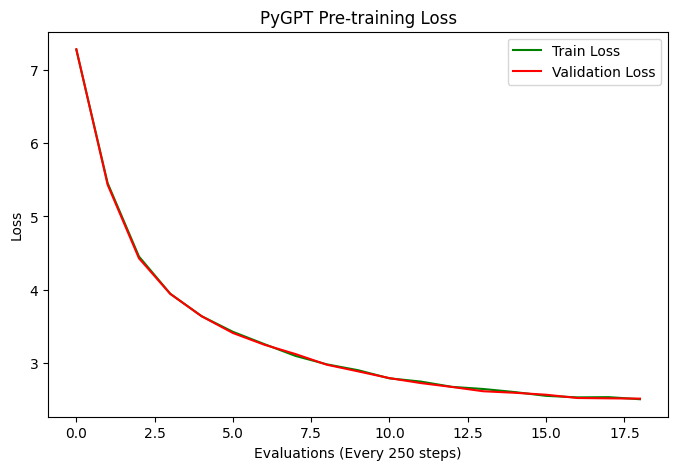

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_loss_list, 'g', label='Train Loss')
plt.plot(validation_loss_list, 'r', label='Validation Loss')
plt.xlabel(f"Evaluations (Every {eval_iters} steps)")
plt.ylabel("Loss")
plt.title("PyGPT Pre-training Loss")
plt.legend()
plt.show()

In [29]:
# Load Best Saved Weights
model.load_state_dict(torch.load(best_model_params_path, map_location=device))
model.eval()

# Prompt 1: Python Function Prompt
prompt_code = "def is_palindrome(s):\n    \"\"\"Check if string is palindrome\"\"\"\n"
context_tokens = torch.tensor(tokenizer.encode(prompt_code)).unsqueeze(0).to(device)

generated_ids = model.generate(context_tokens, max_new_tokens=150, temperature=0.6, top_k=30)
print("--- GENERATED PYTHON CODE ---")
print(tokenizer.decode(generated_ids[0].tolist()))

--- GENERATED PYTHON CODE ---
def is_palindrome(s):
    """Check if string is palindrome"""
if s == "y" and s == "y":
    # If not, recommend applying moisturizer 
    print("Toenails thoroughly.")
elif c == "n":
    # Else print("Toenails regularly"
    print("If you feel over-the-counter pain relief")
    print("• Stay home from home")
elif s == "y":
    print("Toenails regularly")
```Here is a possible implementation of this functionality in Julia:

    # Define input variables
    age = 18
    age = 18
    
    # Determine whether user is eligible for high nose care based on age
    if age < 18
        return "No need for no


In [30]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Create a dedicated directory for your SLM project in Drive
drive_project_dir = '/content/drive/MyDrive/Python_SLM_Project'
os.makedirs(drive_project_dir, exist_ok=True)

print(f"Project directory ready at: {drive_project_dir}")

Mounted at /content/drive
Project directory ready at: /content/drive/MyDrive/Python_SLM_Project


In [32]:
# Change the model path from local directory to Google Drive
best_model_params_path = "/content/drive/MyDrive/Python_SLM_Project/best_code_model.pt"

# Save inside your evaluation loop:
if losses['val'] < best_val_loss:
    best_val_loss = losses['val']
    torch.save(model.state_dict(), best_model_params_path)
    print(f"Saved new best model to Google Drive!")

In [33]:
# Set file paths inside Google Drive
for split_name, dset in [('train', train_ds), ('validation', val_ds)]:
    filename = f"/content/drive/MyDrive/Python_SLM_Project/{split_name}.bin"
    # ... rest of your tokenization & memmap code ...

In [34]:
def get_batch(split):
    if split == 'train':
        data = np.memmap('/content/drive/MyDrive/Python_SLM_Project/train.bin', dtype=np.uint32, mode='r')
    else:
        data = np.memmap('/content/drive/MyDrive/Python_SLM_Project/validation.bin', dtype=np.uint32, mode='r')
    # ... rest of your batching code ...

In [36]:
import os
import shutil
import torch

# Paths
local_model_path = "best_code_model.pt"
drive_model_path = "/content/drive/MyDrive/Python_SLM_Project/best_code_model.pt"

# If the model exists locally but is missing in Google Drive, copy it over
if os.path.exists(local_model_path) and not os.path.exists(drive_model_path):
    print("Backing up local model weights to Google Drive...")
    shutil.copy(local_model_path, drive_model_path)
    print("Backup complete!")

# Load saved model weights across sessions (prefer Google Drive, fallback to local if needed)
model = GPT(config).to(device)

if os.path.exists(drive_model_path):
    checkpoint_path = drive_model_path
    print(f"Loading model weights from Google Drive: {checkpoint_path}")
elif os.path.exists(local_model_path):
    checkpoint_path = local_model_path
    print(f"Loading model weights from local runtime: {checkpoint_path}")
else:
    raise FileNotFoundError("No saved model weights found locally or in Google Drive. Please run the training cell first!")

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

print("Model successfully restored!")

Backing up local model weights to Google Drive...
Backup complete!
Loading model weights from Google Drive: /content/drive/MyDrive/Python_SLM_Project/best_code_model.pt
Model successfully restored!


### 💾 Back up Binary Datasets to Google Drive
This cell copies your tokenized binary files (`train.bin` and `validation.bin`) from the local runtime storage directly into your permanent Google Drive project folder.

In [37]:
import os
import shutil

local_train_path = "train.bin"
local_val_path = "validation.bin"

drive_train_path = "/content/drive/MyDrive/Python_SLM_Project/train.bin"
drive_val_path = "/content/drive/MyDrive/Python_SLM_Project/validation.bin"

# Back up train.bin
if os.path.exists(local_train_path):
    if not os.path.exists(drive_train_path):
        print("Copying train.bin to Google Drive (this may take a minute)...")
        shutil.copy(local_train_path, drive_train_path)
        print("Successfully backed up train.bin!")
    else:
        print("train.bin already exists in Google Drive.")
else:
    print("Local train.bin not found. Make sure you finished the tokenization step!")

# Back up validation.bin
if os.path.exists(local_val_path):
    if not os.path.exists(drive_val_path):
        print("Copying validation.bin to Google Drive...")
        shutil.copy(local_val_path, drive_val_path)
        print("Successfully backed up validation.bin!")
    else:
        print("validation.bin already exists in Google Drive.")
else:
    print("Local validation.bin not found.")

Copying train.bin to Google Drive (this may take a minute)...
Successfully backed up train.bin!
Copying validation.bin to Google Drive...
Successfully backed up validation.bin!


### 🔍 Verify Binary Files in Google Drive
This cell checks if both binary files are present in your Google Drive folder from Python's perspective and displays their file sizes.

In [38]:
import os

drive_train_path = "/content/drive/MyDrive/Python_SLM_Project/train.bin"
drive_val_path = "/content/drive/MyDrive/Python_SLM_Project/validation.bin"

def check_file(path, name):
    if os.path.exists(path):
        size_bytes = os.path.getsize(path)
        size_mb = size_bytes / (1024 * 1024)
        print(f"✅ {name} exists in Google Drive!")
        print(f"   Size: {size_mb:.2f} MB ({size_bytes:,} bytes)\n")
    else:
        print(f"❌ {name} is missing from Google Drive folder!\n")

print("Checking Google Drive files...\n")
check_file(drive_train_path, "train.bin")
check_file(drive_val_path, "validation.bin")

Checking Google Drive files...

✅ train.bin exists in Google Drive!
   Size: 2617.33 MB (2,744,468,020 bytes)

✅ validation.bin exists in Google Drive!
   Size: 137.58 MB (144,261,676 bytes)

